# K-Means

In [41]:
import os
from dotenv import load_dotenv
import pandas as pd
from sqlalchemy import create_engine
import urllib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

load_dotenv("../.env", override=True)

server = os.getenv("SQL_SERVER")
database = os.getenv("SQL_DATABASE")
driver = os.getenv("SQL_DRIVER")
user = os.getenv("SQL_USER")
password = os.getenv("SQL_PASSWORD")

print("Server:", server)
print("Database:", database)
print("Driver:", driver)


Server: 172.24.112.1
Database: ecommerce_xomdata
Driver: ODBC Driver 18 for SQL Server


In [42]:
params = urllib.parse.quote_plus(
    f"DRIVER={{{driver}}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"UID={user};"
    f"PWD={password};"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
    "Connection Timeout=15;"
)

engine = create_engine(
    f"mssql+pyodbc:///?odbc_connect={params}",
    pool_pre_ping=True
)

with engine.connect() as conn:
    print("Kết nối SQL Server thành công!")

Kết nối SQL Server thành công!


In [43]:
sql = """
SELECT *
FROM e_commerce.rfm_features
"""

df = pd.read_sql(sql, engine)

In [44]:
df.head()

,customer_id,first_purchase_date,last_purchase_date,recency,frequency,monetary
0,AA-64570,2022-05-27,2022-05-27,583,1,36.0
1,AB-100601402,2023-11-06,2023-11-06,55,1,36.0
2,AB-25549,2021-09-15,2021-09-15,837,1,36.0
3,AC-1042039,2023-12-25,2023-12-25,6,1,36.0
4,AF-10870118,2022-05-17,2022-05-17,593,1,36.0


In [45]:
print(df.isnull().sum())

print("Frequency = 0:", (df['frequency'] == 0).sum())
print("Monetary <= 0:", (df['monetary'] <= 0).sum())

customer_id            0
first_purchase_date    0
last_purchase_date     0
recency                0
frequency              0
monetary               0
dtype: int64
Frequency = 0: 0
Monetary <= 0: 0


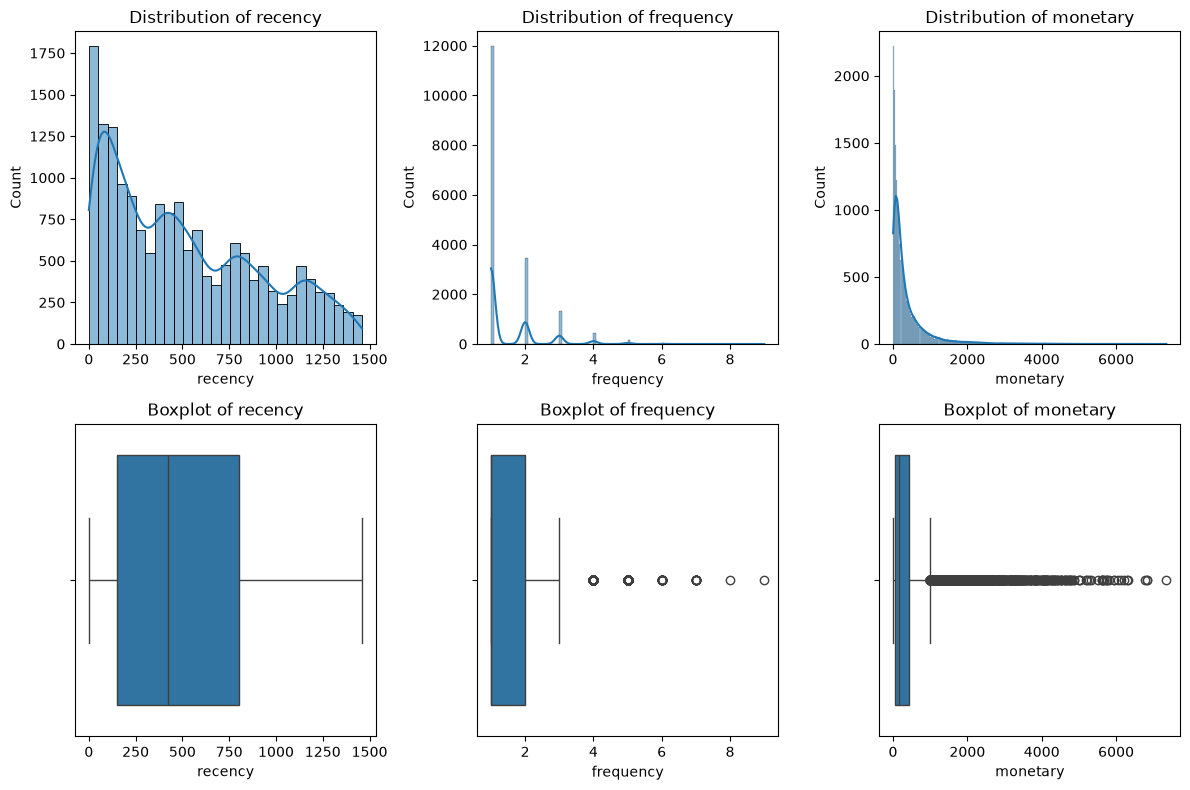

In [46]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, col in enumerate(['recency', 'frequency', 'monetary']):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Distribution of {col}')
    
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

* **Recency** — phân phối khá "khỏe mạnh": trải đều từ 0 đến ~1400 ngày, giảm dần, không có outlier (boxplot không có chấm ngoài whisker) ⇒ *Không cần Log-transform nhiều, có thể giữ nguyên hoặc chỉ cần scale*
* **Frequency** — lệch phải cực mạnh: gần như toàn bộ khách hàng chỉ mua 1 lần, cụm nhỏ mua 2 lần, còn lại (3-9 lần) bị boxplot đánh dấu là "outlier" hàng loạt ⇒ *Cần Log-transform*
* **Monetary** — lệch phải cực mạnh, tương tự: đa số dưới 500, đuôi dài tới 7000+, rất nhiều điểm bị đánh dấu outlier ⇒ *Cần Log-transform*

### Log Transformation

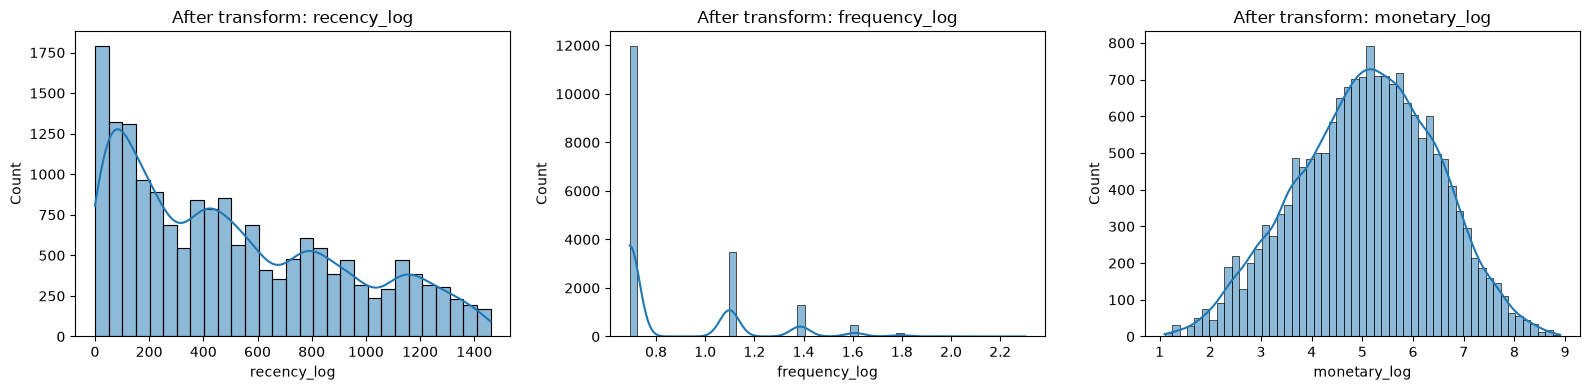

In [47]:
df['recency_log'] = df['recency'] # np.log1p(df['recency']) # giữ nguyên, không cần log
df['frequency_log'] = np.log1p(df['frequency'])
df['monetary_log'] = np.log1p(df['monetary'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['recency_log', 'frequency_log', 'monetary_log']):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f'After transform: {col}')
plt.tight_layout()
plt.show()

### Feature Standardization

In [48]:
from sklearn.preprocessing import StandardScaler
features = df[['recency_log', 'frequency_log', 'monetary_log']]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(features)

df_scaled = pd.DataFrame(
    df_scaled, 
    columns=['recency_scaled', 'frequency_scaled', 'monetary_scaled'],
    index=df.index
)

df_scaled.describe()

,recency_scaled,frequency_scaled,monetary_scaled
count,1.741500e+04,1.741500e+04,1.741500e+04
mean,5.222479e-17,3.133487e-16,6.005851e-16
std,1.000029e+00,1.000029e+00,1.000029e+00
min,-1.265797e+00,-6.125155e-01,-2.928236e+00
25%,-8.963581e-01,-6.125155e-01,-6.835832e-01
50%,-2.148933e-01,-6.125155e-01,3.726843e-02
75%,7.386581e-01,8.472454e-01,7.170316e-01
max,2.378667e+00,5.181804e+00,2.795941e+00


### Determine Optimal Number of Clusters (K)

* Elbow Method
* Silhouette Analysis

In [49]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2,11)

inertia = [] #use for Elbow method
silhouette_scores = [] #use for silhouette score

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(df_scaled)

    inertia.append(kmeans.inertia_)
    sil_score = silhouette_score(df_scaled, labels)
    silhouette_scores.append(sil_score)

    print(f"K={k}: Inertia={kmeans.inertia_: .2f}, Silhouette={sil_score: .4f}")

K=2: Inertia= 32471.29, Silhouette= 0.3767
K=3: Inertia= 22538.28, Silhouette= 0.3659
K=4: Inertia= 17662.76, Silhouette= 0.3460
K=5: Inertia= 14990.91, Silhouette= 0.3374
K=6: Inertia= 12486.46, Silhouette= 0.3393
K=7: Inertia= 11300.97, Silhouette= 0.3438
K=8: Inertia= 10112.96, Silhouette= 0.3316
K=9: Inertia= 9124.66, Silhouette= 0.3326
K=10: Inertia= 8193.50, Silhouette= 0.3368


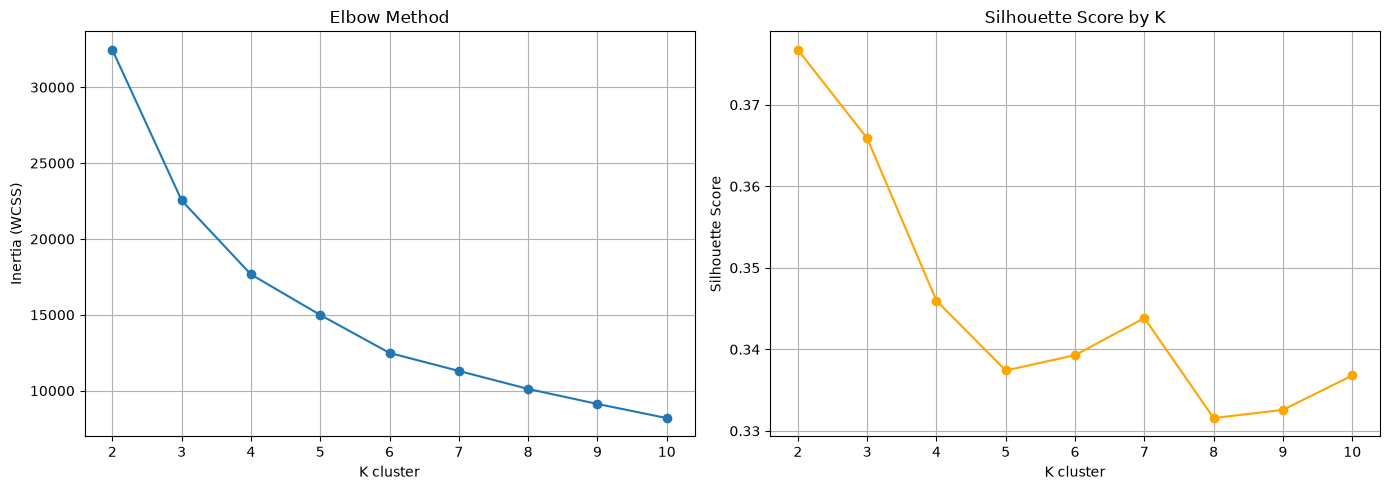

In [50]:
fig, axes = plt.subplots(1, 2, figsize = (14,5))

#Elbow plot
axes[0].plot(k_range, inertia, marker= 'o')
axes[0].set_xlabel('K cluster')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method')
axes[0].grid(True)

# Silhouette plot
axes[1].plot(k_range, silhouette_scores, marker='o', color='orange')
axes[1].set_xlabel('K cluster')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by K')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Elbow Method**: Đường cong giảm mạnh từ K=2→3→4, sau đó độ dốc giảm chậm dần rõ rệt từ K=4 trở đi (đường gần như thẳng, ít gấp khúc thêm). → Điểm "khuỷu tay" nằm ở khoảng K=4.

In [51]:
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(df_scaled)

df

,customer_id,first_purchase_date,last_purchase_date,recency,frequency,monetary,recency_log,frequency_log,monetary_log,cluster
0,AA-64570,2022-05-27,2022-05-27,583,1,36.0,583,0.693147,3.610918,3
1,AB-100601402,2023-11-06,2023-11-06,55,1,36.0,55,0.693147,3.610918,3
2,AB-25549,2021-09-15,2021-09-15,837,1,36.0,837,0.693147,3.610918,1
3,AC-1042039,2023-12-25,2023-12-25,6,1,36.0,6,0.693147,3.610918,3
4,AF-10870118,2022-05-17,2022-05-17,593,1,36.0,593,0.693147,3.610918,3
...,...,...,...,...,...,...,...,...,...,...
17410,SH-199751404,2020-12-09,2023-12-02,29,7,1632.0,29,2.079442,7.398174,2
17411,SH-203951406,2021-10-11,2023-12-08,23,7,465.0,23,2.079442,6.144186,2
17412,SH-2039545,2020-01-06,2023-08-23,130,6,883.0,130,1.945910,6.784457,2
17413,SV-203651406,2020-01-12,2023-09-21,101,7,1516.0,101,2.079442,7.324490,2


In [52]:
print(df.groupby('cluster')[['recency', 'frequency', 'monetary']].mean())


             recency  frequency    monetary
cluster                                    
0         334.523372   1.000000  474.863602
1        1060.164399   1.073749  228.199078
2         269.452425   2.590342  705.016165
3         338.761154   1.053241   42.764111


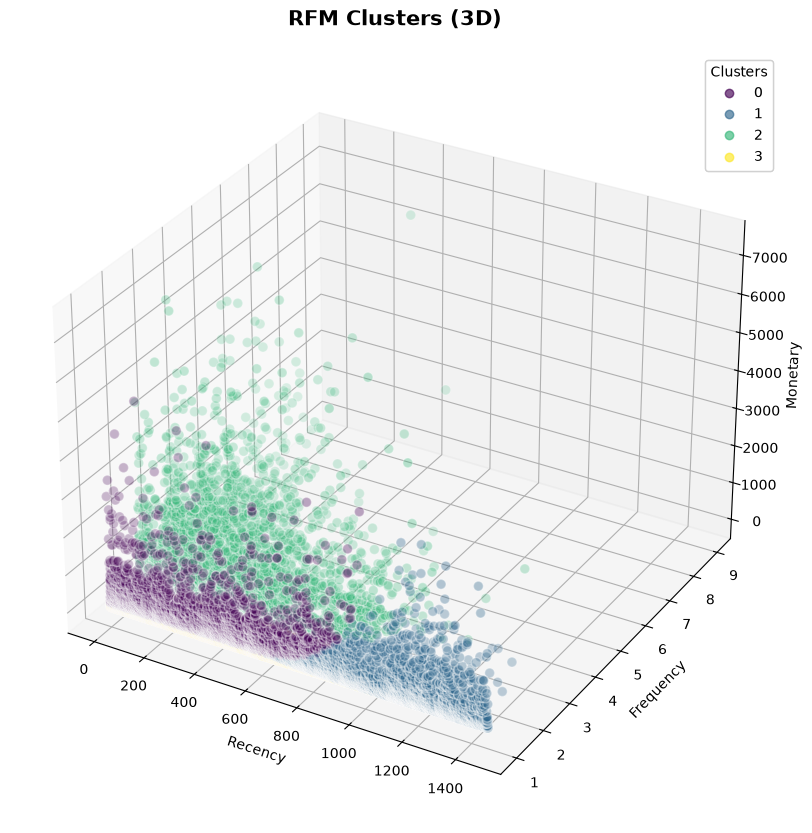

In [53]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(111, projection='3d')

x = df['recency']
y = df['frequency']
z = df['monetary']
colors = df['cluster']

scatter = ax.scatter(x, y, z, c=colors, cmap='viridis', s=50, alpha=0.6, edgecolors='w')

ax.set_xlabel('Recency', fontsize=10)
ax.set_ylabel('Frequency', fontsize=10)
ax.set_zlabel('Monetary', fontsize=10)
plt.title('RFM Clusters (3D)', fontsize=15, fontweight='bold', pad=20)

legend1 = ax.legend(*scatter.legend_elements(), title="Clusters", loc="upper right")
ax.add_artist(legend1)

plt.show()


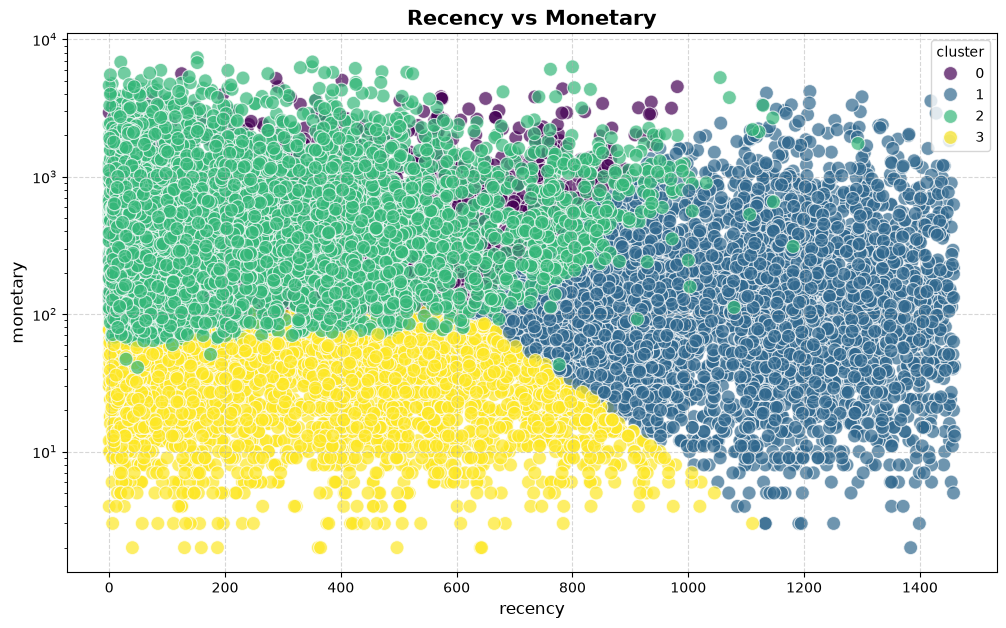

Đặc điểm chi tiết của từng cụm khách hàng:


,recency,frequency,monetary,Count
cluster,,,,
2,269.452425,2.590342,705.016165,4887
0,334.523372,1.000000,474.863602,3915
1,1060.164399,1.073749,228.199078,4556
3,338.761154,1.053241,42.764111,4057


In [54]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='recency', y='monetary', hue='cluster', palette='viridis', s=100, alpha=0.7)

plt.title('Recency vs Monetary', fontsize=15, fontweight='bold')
plt.xlabel('recency', fontsize=12)
plt.ylabel('monetary', fontsize=12)
plt.yscale('log') 
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Tính trung bình các chỉ số theo từng cụm 
cluster_summary = df.groupby('cluster').agg({
    'recency': 'mean',
    'frequency': 'mean',
    'monetary': 'mean',
    'customer_id': 'count'
}).rename(columns={'customer_id': 'Count'}).sort_values(by='monetary', ascending=False)

print("Đặc điểm chi tiết của từng cụm khách hàng:")
display(cluster_summary)

Nhìn vào bảng dữ liệu thể hiện đặc điểm từng khách hàng:
* **Cluster 2:** mua nhiều nhất + chi tiêu nhiều nhất → Frequent Buyers
* **Cluster 0:** mua 1 lần nhưng monetary tương đối cao → Occasional Buyers
* **Cluster 1:** recency 1,060 ngày → Inactive Buyers
* **Cluster 3:** mua ít + monetary rất thấp → Low-Engagement Buyers

In [55]:
cluster_names = {
    0: "Occasional Buyer",
    1: "Inactive Buyer",
    2: "Frequent Buyer",
    3: "Low-Engagement Buyer"
}

df["segmentation"] = df["cluster"].map(cluster_names)

df.head()

,customer_id,first_purchase_date,last_purchase_date,recency,frequency,monetary,recency_log,frequency_log,monetary_log,cluster,segmentation
0,AA-64570,2022-05-27,2022-05-27,583,1,36.0,583,0.693147,3.610918,3,Low-Engagement Buyer
1,AB-100601402,2023-11-06,2023-11-06,55,1,36.0,55,0.693147,3.610918,3,Low-Engagement Buyer
2,AB-25549,2021-09-15,2021-09-15,837,1,36.0,837,0.693147,3.610918,1,Inactive Buyer
3,AC-1042039,2023-12-25,2023-12-25,6,1,36.0,6,0.693147,3.610918,3,Low-Engagement Buyer
4,AF-10870118,2022-05-17,2022-05-17,593,1,36.0,593,0.693147,3.610918,3,Low-Engagement Buyer


In [56]:
df_segmentation = df[[
    "customer_id",
    "last_purchase_date",
    "first_purchase_date",
    "recency",
    "frequency",
    "monetary",
    "cluster",
    "segmentation"
]].copy()

In [57]:
df_segmentation.to_sql(
    "customer_segmentation",
    engine,
    schema="e_commerce",
    if_exists="replace",
    index=False
)

123